# MembershipWoes

**Machine Learning · Exercise 0 · Group 56**  
Yazdan ZandiyeVakili · Amir Saadati · Hani Esreb

This notebook looks at membership status, a few input distributions, and the
main data quality issues in [MembershipWoes (OpenML 44225, version 2)](https://www.openml.org/search?type=data&status=active&id=44225).
It is much larger than Dermatology and has a mix of numbers, categories, and dates.
We describe the data here; model training comes later.

## 1. Setup

Run the cells from top to bottom. We used Python 3.12; internet access is
needed to download the data. Install the packages in your notebook environment:

```bash
python -m pip install numpy pandas matplotlib ipykernel jupyterlab liac-arff
```

Import the libraries and set the plot style. The output records the NumPy and pandas
versions used in this run. The plots stay inside the notebook.

In [1]:
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import arff
%matplotlib inline
plt.rcParams.update({'figure.dpi': 150, 'font.size': 10, 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, TEAL = '#35618D', '#36877E'
print(f'NumPy {np.__version__} | pandas {pd.__version__}')

NumPy 2.3.5 | pandas 2.2.3


## 2. Load the data

Read the ARFF file from OpenML into a DataFrame. Shorten the date column names
and keep the missing values as they are.

In [2]:
url = 'https://www.openml.org/data/v1/download/22106810/MembershipWoes.arff'
source = arff.loads(urlopen(url).read().decode())
df = pd.DataFrame(source['data'], columns=[name.split()[0] for name, kind in source['attributes']])
print(f'{len(df):,} records, {df.shape[1] - 1} non-target columns, 1 target')

10,362 records, 14 non-target columns, 1 target


## 3. Attribute types and ranges

There are 14 columns besides the target, including the membership ID.
Some columns contain numbers but represent categories, such as occupation codes.

| Columns | Type |
| :--- | :--- |
| Term, fees, income, age at issue, additional members | Quantitative: durations, amounts, age, and counts |
| Marital status, gender, occupation code, package, payment mode, agent code | Nominal categories |
| Start and end dates | Dates |
| Membership number | Identifier |
| Membership status | Nominal target: `INFORCE` or `CANCELLED` |

The table below shows the numeric ranges and medians. We also count IDs,
agent codes, and zero ages or fees. The source does not specify a currency.

In [3]:
quantitative = ['MEMBERSHIP_TERM_YEARS', 'ANNUAL_FEES', 'MEMBER_ANNUAL_INCOME',
                'MEMBER_AGE_AT_ISSUE', 'ADDITIONAL_MEMBERS']
display(df[quantitative].agg(['count', 'min', 'median', 'max']).T.round(2))
print(f"Unique membership IDs: {df['MEMBERSHIP_NUMBER'].nunique():,}")
print(f"Agent categories: {df['AGENT_CODE'].nunique():,}")
print(f"Zero ages: {(df['MEMBER_AGE_AT_ISSUE'] == 0).sum()}; zero fees: {(df['ANNUAL_FEES'] == 0).sum()}")

,count,min,median,max
MEMBERSHIP_TERM_YEARS,10362.0,9.0,19.00,102.0
ANNUAL_FEES,10362.0,0.0,118209.28,10100000.0
MEMBER_ANNUAL_INCOME,8608.0,9996.0,549996.00,999999996.0
MEMBER_AGE_AT_ISSUE,10362.0,0.0,46.00,92.0
ADDITIONAL_MEMBERS,10362.0,0.0,1.00,3.0


Unique membership IDs: 10,362
Agent categories: 4,317
Zero ages: 4; zero fees: 1


Fees and income cover large ranges. Ages run from 0 to 92, and membership
terms reach 102 years. These unusual values need checking before we decide what
to do with them. Each of the 10,362 records has a different ID, and there are
4,317 agent codes.

## 4. Missing values

Count missing values by column and as a percentage of all records.
We also check for duplicate rows, both with and without the ID.

In [4]:
missing = pd.DataFrame({'Missing': df.isna().sum(), 'Percent': df.isna().mean() * 100})
display(missing.loc[missing['Missing'] > 0].round(2))
print(f'Rows with any missing value: {df.isna().any(axis=1).sum():,} / {len(df):,}')
print(f'Complete duplicate rows: {df.duplicated().sum()}')
print(f"Repeated profiles after excluding ID: {df.drop(columns='MEMBERSHIP_NUMBER').duplicated().sum()}")

,Missing,Percent
MEMBER_MARITAL_STATUS,2597,25.06
MEMBER_GENDER,611,5.90
MEMBER_ANNUAL_INCOME,1754,16.93
MEMBER_OCCUPATION_CD,43,0.41
END_DATE,7219,69.67


Rows with any missing value: 8,024 / 10,362
Complete duplicate rows: 0
Repeated profiles after excluding ID: 60


### Missing values by field

The bars show how much data is missing in each affected field. Labels give both
the percentage and count. We check end dates separately below because they may
be linked to cancellation rather than simply missing information.

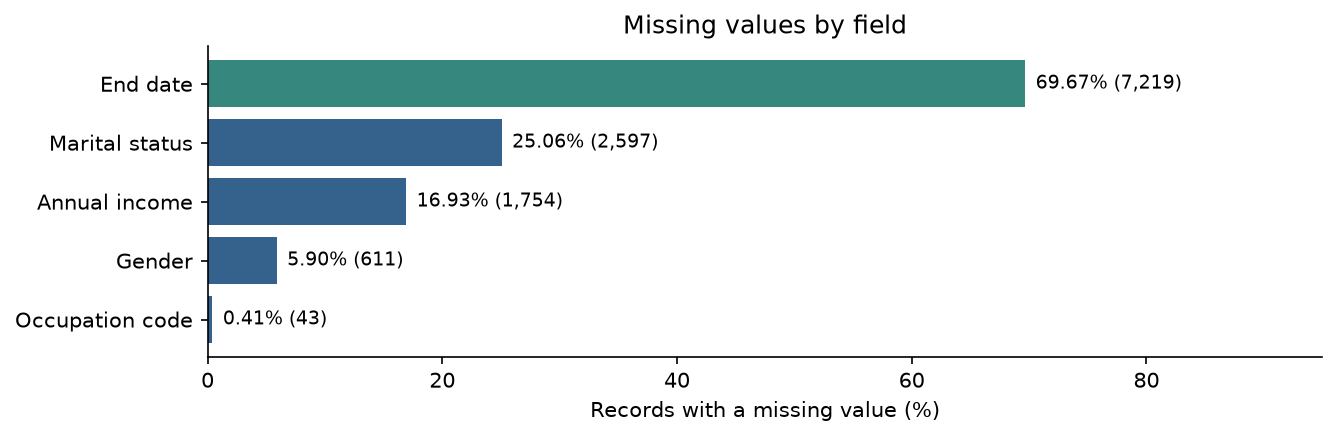

In [5]:
missing_fields = missing.loc[missing['Missing'] > 0].sort_values('Missing', ascending=False)
missing_labels = ['End date', 'Marital status', 'Annual income', 'Gender', 'Occupation code']
fig, ax = plt.subplots(figsize=(8.8, 2.8), layout='constrained')
bars = ax.barh(missing_labels, missing_fields['Percent'], color=[TEAL] + [BLUE] * 4)
ax.bar_label(bars, labels=[f'{p:.2f}% ({n:,})' for p, n in
                          zip(missing_fields['Percent'], missing_fields['Missing'])],
             padding=5, fontsize=9)
ax.set(xlim=(0, 95), xticks=[0, 20, 40, 60, 80], xlabel='Records with a missing value (%)',
       title='Missing values by field')
ax.invert_yaxis()
plt.show()

There is at least one missing value in 8,024 rows (77.44%). Dropping all these
rows would lose most of the data. After removing the ID, 60 rows repeat an
earlier profile. This alone does not tell us whether they refer to the same people.

## 5. Target and input distributions

Count active and cancelled memberships, then calculate their shares of the
dataset. The counts should add up to all 10,362 records.

In [6]:
class_counts = df['MEMBERSHIP_STATUS'].value_counts().reindex(['INFORCE', 'CANCELLED'])
class_table = pd.DataFrame({'Count': class_counts, 'Percent': class_counts / len(df) * 100})
display(class_table.round(2))

,Count,Percent
MEMBERSHIP_STATUS,,
INFORCE,7219,69.67
CANCELLED,3143,30.33


### Status and age

Plot the two target classes beside an age histogram with five-year bins.
The histogram includes zero ages. These plots show the two distributions
separately; they do not compare cancellation across ages.

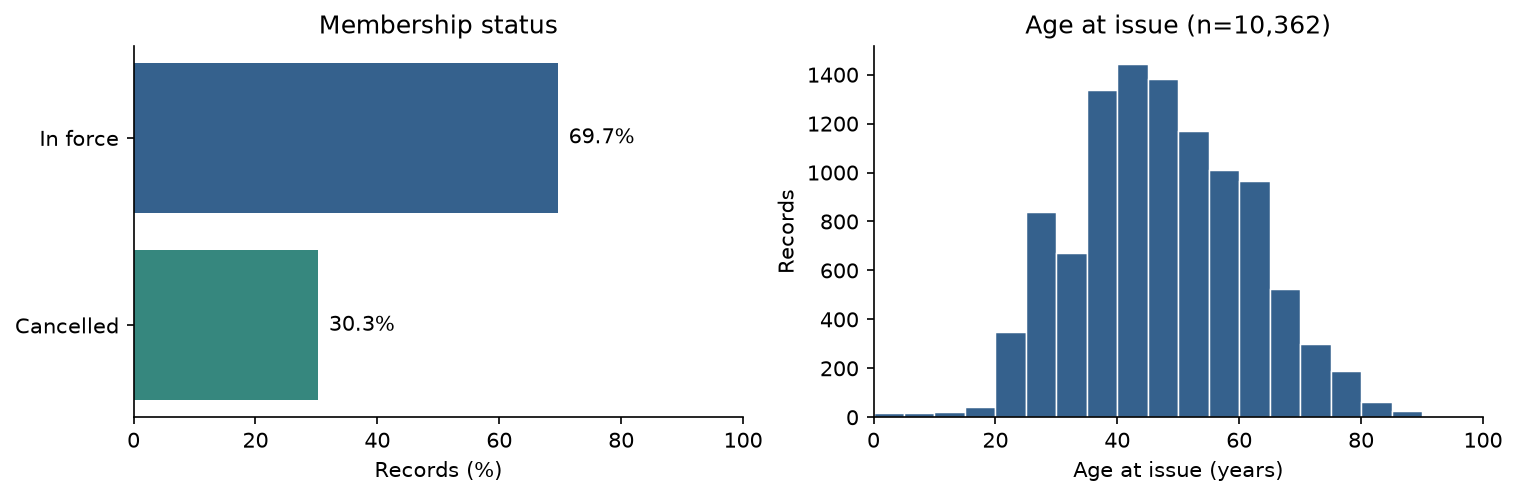

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout='constrained')
bars = axes[0].barh(['In force', 'Cancelled'], class_table['Percent'], color=[BLUE, TEAL])
axes[0].bar_label(bars, fmt='%.1f%%', padding=5)
axes[0].set(xlim=(0, 100), xlabel='Records (%)', title='Membership status')
axes[0].invert_yaxis()
age_bins = np.arange(0, 101, 5)
axes[1].hist(df['MEMBER_AGE_AT_ISSUE'], bins=age_bins, color=BLUE,
             edgecolor='white', linewidth=0.7)
axes[1].set(xlabel='Age at issue (years)', ylabel='Records',
            title=f'Age at issue (n={len(df):,})', xlim=(0, 100))
plt.show()

Most memberships are in force (69.67%); 30.33% are cancelled. Both classes have
many records, but the difference in size will matter when evaluating a model.
The median age at issue is 46 years.

### Annual fees

Fees have a large range, so we plot `log10(1 + fee)` to make the distribution
easier to see. Adding 1 keeps the zero fee in the plot. The earlier table gives
the original values.

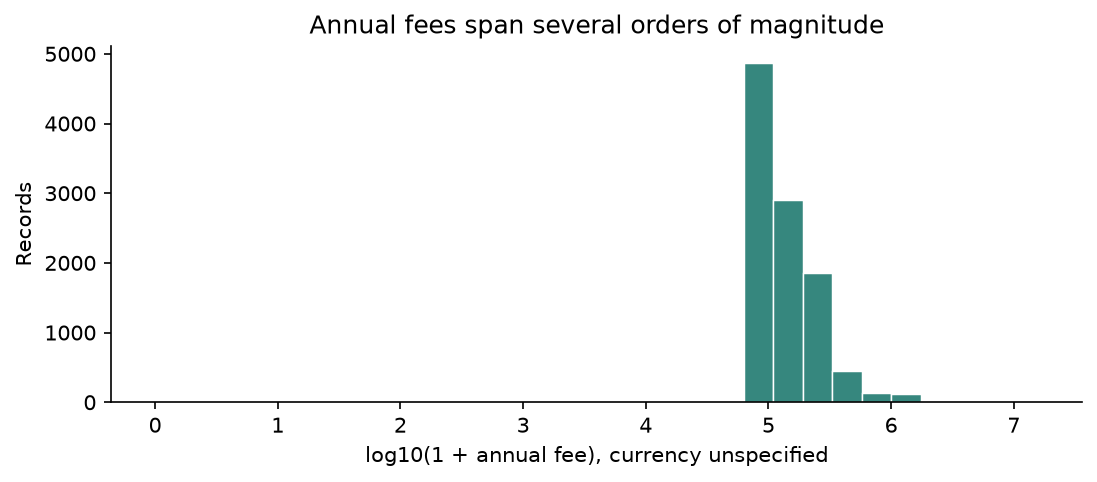

In [8]:
fees = df['ANNUAL_FEES'].dropna()
fig, ax = plt.subplots(figsize=(7.2, 3.1), layout='constrained')
ax.hist(np.log10(1 + fees), bins=np.linspace(0, 7.2, 31), color=TEAL,
        edgecolor='white', linewidth=0.7)
ax.set(xlabel='log10(1 + annual fee), currency unspecified', ylabel='Records',
       title='Annual fees span several orders of magnitude')
plt.show()

The median fee is 118,209.28, well below the maximum of 10,100,000.
The log scale helps show this spread without changing the stored values.

### Payment mode

Compare payment categories using percentages, with counts beside the bars.
These categories have no numeric order.

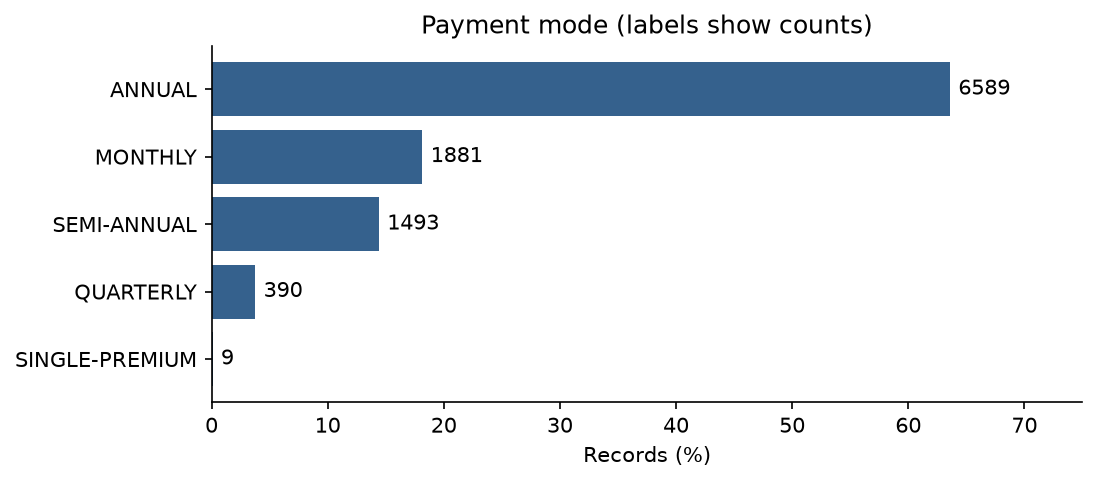

In [9]:
payment_order = ['ANNUAL', 'MONTHLY', 'SEMI-ANNUAL', 'QUARTERLY', 'SINGLE-PREMIUM']
payment_counts = df['PAYMENT_MODE'].value_counts().reindex(payment_order)
fig, ax = plt.subplots(figsize=(7.2, 3.1), layout='constrained')
bars = ax.barh(payment_order, payment_counts / len(df) * 100, color=BLUE)
ax.bar_label(bars, labels=payment_counts, padding=4)
ax.set(xlim=(0, 75), xlabel='Records (%)', title='Payment mode (labels show counts)')
ax.invert_yaxis()
plt.show()

Annual payment is the most common option (6,589 records). Only nine records
use single-premium payment, so some categories will have very few examples
when we later train a model.

### Cancellation by package

Calculate the percentage cancelled within each package. Each bar uses that
package's total as its denominator. The dashed line shows the overall rate.
This comparison cannot tell us whether the package itself affects cancellation.

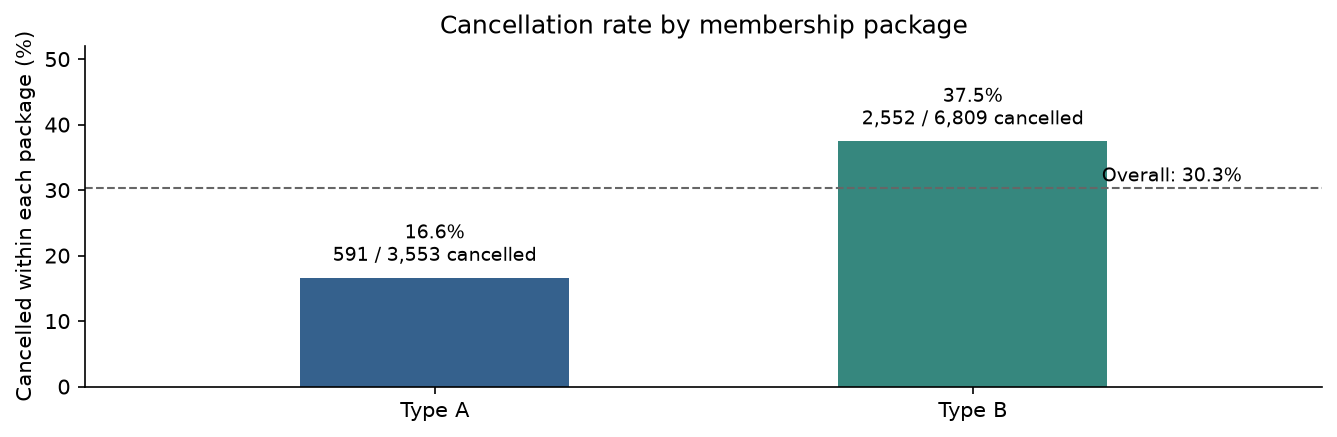

In [10]:
package_counts = pd.crosstab(df['MEMBERSHIP_PACKAGE'], df['MEMBERSHIP_STATUS']).reindex(['TYPE-A', 'TYPE-B'])
package_totals = package_counts.sum(axis=1)
package_rates = package_counts['CANCELLED'] / package_totals * 100
fig, ax = plt.subplots(figsize=(8.8, 2.8), layout='constrained')
bars = ax.bar(['Type A', 'Type B'], package_rates, color=[BLUE, TEAL], width=0.5)
ax.bar_label(bars, labels=[f'{p:.1f}%\n{n:,} / {total:,} cancelled' for p, n, total in
                          zip(package_rates, package_counts['CANCELLED'], package_totals)],
             padding=5, fontsize=9)
overall_rate = (df['MEMBERSHIP_STATUS'] == 'CANCELLED').mean() * 100
ax.axhline(overall_rate, color='#666666', linestyle='--', linewidth=1)
ax.text(1.5, overall_rate + 1, f'Overall: {overall_rate:.1f}%', ha='right', fontsize=9)
ax.set(ylim=(0, 52), xlim=(-0.65, 1.65), ylabel='Cancelled within each package (%)',
       title='Cancellation rate by membership package')
plt.show()

Type A has 591 cancellations out of 3,553 records (16.63%). Type B has
2,552 out of 6,809 (37.48%). Package may be useful for later modelling, although
the two groups could differ in other ways too.

### End dates

Compare end-date availability with membership status. An end date may
give away whether a membership was cancelled.

In [11]:
end_date_by_status = pd.crosstab(df['MEMBERSHIP_STATUS'], df['END_DATE'].notna())
end_date_by_status.columns = ['End date missing', 'End date present']
display(end_date_by_status)

,End date missing,End date present
MEMBERSHIP_STATUS,,
CANCELLED,0,3143
INFORCE,7219,0


Every cancelled membership has an end date, while every in-force membership
has no end date. A model could use this to identify cancellations without
learning anything useful for advance prediction. We should leave out the end
date and a missing-end-date flag unless we know they are available at prediction
time. Removing the ID and end date leaves 12 possible inputs.

## Source

OpenML, *MembershipWoes*, dataset 44225, version 2.
[Metadata](https://www.openml.org/api/v1/json/data/44225) and
[ARFF file](https://www.openml.org/data/v1/download/22106810/MembershipWoes.arff).
Accessed 24 October 2026. The metadata names VARSHA PANDEY as creator and lists
the licence as “Unknown”. It does not explain the currency or all category codes.
The report uses these results and the missing-values and package plots.